In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import IterableDataset, DataLoader
import cudf
import cupy as cp
import numpy as np
import os
import fsspec
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score
import dask_cudf
from dask.distributed import Client, progress
from dask_cuda import LocalCUDACluster
from torch.cuda.amp import autocast, GradScaler
import dask.dataframe as dd
import dask.array as da
from torch.utils.data import DataLoader, Dataset
import pandas as pd
import pyarrow.parquet as pq
import torch.optim as optim
import ast
import torch.nn.functional as F
import dask.dataframe as dd
from tqdm.auto import tqdm # For progress bar


In [2]:
#torch.set_float32_matmul_precision('high')
#torch.backends.cuda.matmul.fp32_precision = 'ieee'


# 1. New API for TF32 control (removes the deprecation warning)
torch.backends.cuda.matmul.fp32_precision = 'tf32' 

# 2. Enables high precision (TF32) for better Inductor/GPU performance 
# (removes the performance warning)
torch.set_float32_matmul_precision('high')



/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/torch/__init__.py:1624: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


In [3]:
#import dask
#import dask_cuda
#import cudf
#import cupy
#from dask.distributed import Client, LocalCluster
#from dask_cuda import LocalCUDACluster
#import dask_cudf
#import os

# --- Configuration for Resource Usage ---
# Get total memory from nvidia-smi output (49140 MiB for RTX A6000)
# Convert MiB to Bytes: 49140 * 1024 * 1024 = 51520630784 Bytes
TOTAL_GPU_MEMORY_BYTES = 97887 * 1024 * 1024 

# Desired usage percentage
GPU_MEMORY_PERCENTAGE_TO_USE = 0.70 # 70%

# Calculate the memory limit for each worker
# LocalCUDACluster by default launches one worker per available GPU.
# So, if you have one A6000, one worker will use 70% of its memory.
DEVICE_MEMORY_LIMIT = int(TOTAL_GPU_MEMORY_BYTES * GPU_MEMORY_PERCENTAGE_TO_USE)

# You can optionally specify which GPUs to use if you have multiple
# and want to restrict to certain ones.
# For a single A6000, this is often not necessary unless you have other processes.
# CUDA_VISIBLE_DEVICES = "0" # Use only GPU 0

# --- Dask Cluster Setup ---
print(f"Setting device_memory_limit per worker to: {DEVICE_MEMORY_LIMIT / (1024**3):.2f} GB ({GPU_MEMORY_PERCENTAGE_TO_USE*100:.0f}% of total GPU memory)")

# 1. Start a Local Dask Cluster with GPU resources
# We pass the calculated device_memory_limit here.
# n_workers can be specified if you have multiple GPUs and want to use a subset.
# threads_per_worker is generally 1 for Dask-CUDA with cuDF/CuPy for best performance
# due to how CUDA streams and contexts are managed, especially if using RMM pools.
cluster = LocalCUDACluster(
    device_memory_limit=DEVICE_MEMORY_LIMIT,
    # Crucial for large workloads and preventing OOM:
    enable_cudf_spill=True, # Enable cuDF's native spilling to host if GPU memory is exhausted

    # Optional UCX for performance (requires ucx-py installed)
    protocol="ucx",
    enable_tcp_over_ucx=True,

    # threads_per_worker is generally 1 for CUDA workloads with cuDF/CuPy
    threads_per_worker=1,
)
client = Client(cluster)

print("\nDask Dashboard Link:", client.dashboard_link)
print("------------------------------------------")
print("Dask Client Info:")
print(client)
print("------------------------------------------")


Setting device_memory_limit per worker to: 66.91 GB (70% of total GPU memory)


/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/rapids_dask_dependency/patches/distributed/comm/__rdd_patch_ucx.py:572: FutureWarning: you have requested protocol='ucx', which now defaults to UCXX but
the package 'distributed-ucxx' is not installed. The current version
of Distributed will fallback to using UCX-Py, but this fallback is
deprecated and will be removed in the next release (RAPIDS 25.10).
To silence this warning and use UCXX, install the 'distributed-ucxx'
package, or to use UCX-Py and silence the warning, use
'protocol="ucx-old"' when you create your Distributed or Dask-CUDA
cluster.                
  warnings.warn(
/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/rapids_dask_dependency/patches/distributed/comm/__rdd_patch_ucx.py:572: FutureWarning: you have requested protocol='ucx', which now defaults to UCXX but
the package 'distributed-ucxx' is not installed. The current version
of Distributed will fallback to using UCX-Py, but this 


Dask Dashboard Link: http://127.0.0.1:8787/status
------------------------------------------
Dask Client Info:
<Client: 'ucx://127.0.0.1:41129' processes=1 threads=1, memory=0.98 TiB>
------------------------------------------


In [3]:
import random
def set_seed(seed=42):
  np.random.seed(seed) 
  random.seed(seed)
set_seed()
try:
    torch.multiprocessing.set_start_method('spawn', force=True)
    print("Multiprocessing start method set to 'spawn'.")
except RuntimeError:
    print("Multiprocessing start method is already set.")

Multiprocessing start method set to 'spawn'.


In [4]:
PATH_RESNET_species = f"../cnn_kraken_species/checkpoints/best_resnet_classifier__fast_phase4.pt" 
PATH_RESNET_species_finetuned = f"../cnn_kraken/checkpoint_finetune_resnet/finetune_noise_14.pt"
PATH_CONVNEXT_zero_species = f"../cnn_kraken/checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt" 
PATH_CONVNEXT_transfer_species =f"../cnn_kraken/checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt"
PATH_CONVNEXT_fine_species =  f"../cnn_kraken/checkpoint_transfer_species_conv/finetune_noise_7.pt"
PATH_RESNET_genus = f"../cnn_kraken_genus/best_resnet_classifier__fast_phase4.pt" 
PATH_CONVNEXT_genus = f"../cnn_kraken/checkpoint_genus_conv/best_convnext_classifier_fast_phase4_2.pt" 

In [5]:
mapping_csv_path_genus = f"../dataset_kraken/genus_name_ids.csv"
mapping_csv_path_species = f"../dataset_kraken/species_name_ids.csv"

In [6]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES_species = 13683
NUM_CLASSES_genus = 2702
MAX_SEQUENCE_LENGTH = 512
NUM_FEATURES = 4
BATCH_SIZE = 1024 
fs = fsspec.filesystem('file')
test_file_paths_species = fs.glob(os.path.join(f"./processed_kraken_species_splited_parquet/test", '*.parquet'))
NUCLEOTIDES = ['A', 'C', 'G', 'T']
PADDED_COLUMN = 'sequence_padded'
LABEL_COLUMN = 'label'




<h1>Inference</h1>

In [7]:
models = [
    {
        "model_name":"ConvNext finetuned",
        "path":PATH_CONVNEXT_fine_species,
        "type":"CONVNEXT_FINE"
        
    },
    {
        "model_name":"ConvNext from scratch",
        "path":PATH_CONVNEXT_zero_species,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ConvNext transfer from genus",
        "path":PATH_CONVNEXT_transfer_species,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ResNet50",
        "path":PATH_RESNET_species,
        "type":"RESNET"
    },
    {
        "model_name":"ResNet50_finetuned",
        "path":PATH_RESNET_species_finetuned,
        "type":"RESNET_FINE"
    },
]

In [35]:
def load_model(model_dict):
    if model_dict["type"] == "CONVNEXT":
        model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES_species, debug=False, dropout_rate=0.5)
        model.to(DEVICE)
        try:
            print(f"Carregando pesos de: {model_dict["path"]}")
            state_dict = torch.load(model_dict["path"])
            
            # Limpeza de chaves se necessário (caso venha de torch.compile)
            new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
            if "model_state_dict" in new_state_dict:
                new_state_dict = new_state_dict["model_state_dict"]
                
            model.load_state_dict(new_state_dict)
            print("Sucesso! Modelo carregado. Iniciando Fase de Refinamento.")
        except Exception as e:
            print(f"ATENÇÃO: Não foi possível carregar o checkpoint: {e}")
            print("Verifique o caminho do arquivo. Se prosseguir, será um treino do zero (não recomendado agora).")
    elif model_dict["type"] == "RESNET":
        model = resnet50_1d(MAX_SEQUENCE_LENGTH,NUM_FEATURES,NUM_CLASSES_species,debug=False,dropout_rate=0.5)
        model.to(DEVICE)
        

        model = torch.compile(model)
        
        try:
            model.load_state_dict(torch.load(model_dict["path"]))
            print(f"Melhor modelo carregado")
        except FileNotFoundError:
            print(f"Aviso: não encontrado. O teste usará o modelo no seu estado atual.")

    elif model_dict["type"] == "CONVNEXT_FINE":
        model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES_species, debug=False, dropout_rate=0.7)
        model.to(DEVICE)
        model = torch.compile(model)
        try:
            print(f"Carregando pesos de: {PATH_CONVNEXT_fine_species}")
            state_dict = torch.load(PATH_CONVNEXT_fine_species)
            
            # Limpeza de chaves se necessário (caso venha de torch.compile)
            new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
            if "model_state_dict" in new_state_dict:
                new_state_dict = new_state_dict["model_state_dict"]
                
            model.load_state_dict(new_state_dict)
            print("Sucesso! Modelo carregado. Iniciando Fase de Refinamento.")
        except Exception as e:
            print(f"ATENÇÃO: Não foi possível carregar o checkpoint: {e}")
            print("Verifique o caminho do arquivo. Se prosseguir, será um treino do zero.")
    elif model_dict["type"] == "RESNET_FINE":
        #print(torch.load(model_dict["path"]).keys())
        model = resnet50_1d(MAX_SEQUENCE_LENGTH,NUM_FEATURES,NUM_CLASSES_species,debug=False,dropout_rate=0.5)
        model.to(DEVICE)
        

        model = torch.compile(model)
        
        try:
            model.load_state_dict(torch.load(model_dict["path"])['model_state_dict'])
            print(f"Melhor modelo carregado")
        except FileNotFoundError:
            print(f"Aviso: não encontrado. O teste usará o modelo no seu estado atual.")

    print(type(model))
    print(type(model).__name__)
    return model

dict_keys(['epoch', 'model_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'scaler_state_dict', 'metrics'])
Melhor modelo carregado
<class 'torch._dynamo.eval_frame.OptimizedModule'>
OptimizedModule


In [11]:
import sys
import os

# 1. Pega o diretório atual
current_dir = os.getcwd()

# 2. Pega o diretório pai (um nível acima)
parent_dir = os.path.dirname(current_dir)

# 3. Adiciona o pai ao caminho de busca do Python
sys.path.append(parent_dir)
# --- DEBUG (Opcional) ---
# Verifica se a pasta cnn_kraken realmente existe no pai
path_to_check = os.path.join(parent_dir, 'cnn_kraken')
if os.path.exists(path_to_check):
    print(f"✅ Pasta 'cnn_kraken' encontrada em: {path_to_check}")
else:
    print(f"❌ AVISO: Não encontrei 'cnn_kraken' em {parent_dir}. Verifique o caminho.")
    
from cnn_kraken.utils.analize_funcs import *
from cnn_kraken.utils.models import *
from cnn_kraken.utils.dna_dataset_2 import DaskCuDFIntegerDataset, ParquetCPUDataset
import fsspec

✅ Pasta 'cnn_kraken' encontrada em: /home/mlima/workspace/cnn_kraken


In [12]:
base_dir = f"./processed_ncbi_splited_parquet"
test_path = os.path.join(base_dir, 'test')

test_dataset = dd.read_parquet(test_path, blocksize="100MB")
test_dataset.head()

,species_id,genus_id,origin_len,read_len,sequence
41844,256,32,4735,3399,TTGATGTCATTGCACTGACTTCAAGTCTGCACGTTCCTGTACAGAA...
10992,87,2606,1088,1027,TCCCTCGTGAAAGTGTGTCCAGCTCGGGAACCAAACGCGGTAACCC...
16207,114,9,3634,1674,GCTAGCTACTTACGTAGAATGCTTGCAGATTTACCTGAAGGCACAG...
37361,223,31,7350,1538,GGAAGTTAGAAGGAAGGATGGGGGAATTTTCGATCCTGAAGCATAT...
41210,252,32,5175,3945,ATGAGGAGACCGCGCCTGTCGTCAGGTGCGTTATTAATGGTCGGAT...


In [13]:
# Configurações
WINDOW_SIZE = 512
STRIDE = 256  # 256 = 50% de overlap (melhora a precisão), 512 = sem overlap (mais rápido)
BATCH_SIZE_INFERENCE = 2048 # Quantas janelas processar de uma vez na GPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Mapeamento (O mesmo usado no treino)
DNA_MAP = {'A': 0, 'C': 1, 'G': 2, 'T': 3}

def text_to_tensor(seq_str, window_size, stride):
    """
    Fatia a sequência em janelas e retorna índices INTEIROS.
    Retorna: Tensor [N_windows, window_size] (dtype=torch.long)
    """
    seq_len = len(seq_str)
    windows = []
    
    # Gera as janelas
    for start in range(0, seq_len - window_size + 1, stride):
        window_str = seq_str[start : start + window_size]
        
        # Converte para índices (0, 1, 2, 3, 4)
        indices = [DNA_MAP.get(base, 4) for base in window_str]
        windows.append(indices)
    
    if not windows:
        return None

    # RETORNA APENAS INTEIROS (Rank 2)
    # Shape: [N_windows, 512]
    # O modelo vai receber isso e transformar em [N, 4, 512] internamente
    return torch.tensor(windows, dtype=torch.long)

In [14]:
def run_inference_on_long_reads(model, df_long_reads, output_path):
    df_map = pd.read_csv("mapping_species_final.csv")
    # Cria o dicionário: Índice (0..N) -> TaxID Real
    print("criando dicionario")
    idx_to_taxid = dict(zip(df_map['new_model_label'], df_map['tax_id_original']))
    print("dicionario criado")
    
    model.eval()
    model.to(DEVICE)
    
    results = []
    
    print(f"Iniciando inferência em {len(df_long_reads)} sequências longas...")
    
    with torch.no_grad():
        for idx, row in tqdm(df_long_reads.iterrows(), total=len(df_long_reads)):
            
            original_seq = row['sequence']
            true_species = row['species_id']
            true_genus = row['genus_id']
            read_id = idx # Ou use row['id'] se tiver
            
            # 1. Prepara as janelas (Slicing)
            batch_tensor = text_to_tensor(original_seq, WINDOW_SIZE, STRIDE)
            
            if batch_tensor is None:
                continue
            
            batch_tensor = batch_tensor.to(DEVICE)
            
            # 2. Inferência (Se houver muitas janelas, processamos em mini-batches para não estourar VRAM)
            # Ex: Uma sequência de 100k bp gera centenas de janelas.
            num_windows = batch_tensor.size(0)
            all_logits = []
            
            for i in range(0, num_windows, BATCH_SIZE_INFERENCE):
                mini_batch = batch_tensor[i : i + BATCH_SIZE_INFERENCE]
                
                # Forward Pass
                logits = model(mini_batch) # Shape: [MiniBatch, Num_Classes]
                all_logits.append(logits.cpu())
                
            # Concatena todos os resultados daquela sequência
            full_logits = torch.cat(all_logits, dim=0) # Shape: [Total_Windows, Num_Classes]
            
            # 3. Coleta Estatísticas
            # Probabilidades (Softmax)
            probs = F.softmax(full_logits, dim=1)
            
            # Top 5 para cada janela
            top5_probs, top5_indices = torch.topk(probs, k=5, dim=1)
            
            # Armazenamos os dados. 
            # ATENÇÃO: Salvar os logits brutos de TODAS as classes ocupa muito espaço.
            # Recomendação: Salvar apenas os Top-5 Logits/Indices e a Média Global.
            
            # Média dos Logits (Técnica: Average Pooling)
            mean_logits = full_logits.mean(dim=0)
            top5_mean_val, top5_mean_idx = torch.topk(mean_logits, k=5)
            
            # Voto Majoritário (Hard Voting) - Qual classe ganhou mais janelas?
            winners = torch.argmax(probs, dim=1)
            majority_class = torch.mode(winners).values.item()

            results.append({
                'read_index': read_id,
                'species_true': true_species,
                'genus_true': true_genus,
                'num_windows': num_windows,
                
                # Resultados Agregados (Já calculados para facilitar)
                'pred_majority_vote': majority_class,
                'pred_mean_logits': top5_mean_idx[0].item(),
                
                # Dados Crus (Para você brincar depois)
                # Convertemos para lista python para salvar em parquet/json
                'window_top5_indices': top5_indices.numpy().tolist(),
                'window_top5_probs': top5_probs.numpy().tolist(),
                
                # Opcional: Se quiser guardar os logits raw de TUDO (Cuidado com espaço em disco!)
                # 'full_logits_mean': mean_logits.numpy().tolist() 
            })

    # 4. Salva o Resultado
    # No loop de inferência ou ao salvar o DataFrame final:
    
    df_results = pd.DataFrame(results)
    df_results['real_tax_id'] = df_results['species_true'].map(idx_to_taxid)
    df_results.to_parquet(output_path)
    print(f"Resultados salvos em: {output_path}")
    return df_results


In [41]:


import os
for model_dict in models:
    print(f"carregando modelo:{model_dict["model_name"]}")
    path = f"resultados_inferencia_long_reads_{model_dict["model_name"]}.parquet"
    print(model_dict["type"])
    print("rodando inferencia")    
    if os.path.exists(path):
        print("skiping já rodou")
    else:
        model = load_model(model_dict)
        df_final = run_inference_on_long_reads(model, test_dataset, path)
    print("pronto")
    print("*"*20)


carregando modelo:ConvNext finetuned
CONVNEXT_FINE
rodando inferencia
skiping já rodou
pronto
********************
carregando modelo:ConvNext from scratch
CONVNEXT
rodando inferencia
skiping já rodou
pronto
********************
carregando modelo:ConvNext transfer from genus
CONVNEXT
rodando inferencia
skiping já rodou
pronto
********************
carregando modelo:ResNet50
RESNET
rodando inferencia
skiping já rodou
pronto
********************
carregando modelo:ResNet50_finetuned
RESNET_FINE
rodando inferencia
Melhor modelo carregado
<class 'torch._dynamo.eval_frame.OptimizedModule'>
OptimizedModule
criando dicionario
dicionario criado
Iniciando inferência em 435050 sequências longas...


  0%|          | 0/435050 [00:00<?, ?it/s]

Resultados salvos em: resultados_inferencia_long_reads_ResNet50_finetuned.parquet
pronto
********************


<h1>ConvNext Species(from FineTuning)</h1>

In [42]:
mapping_csv_path_genus = f"../dataset_kraken/genus_name_ids.csv"
mapping_csv_path_species = f"../dataset_kraken/species_name_ids.csv"
mapping_new_csv_path_species = f"mapping_species_final.csv"
mapping_new_csv_path_genus = f"mapping_genus_final.csv"

df_map_species = pd.read_csv(mapping_csv_path_species)
df_map_genus  = pd.read_csv(mapping_csv_path_genus)
df_newmap_species = pd.read_csv(mapping_new_csv_path_species)
df_newmap_genus  = pd.read_csv(mapping_new_csv_path_genus)

In [43]:
df = pd.read_parquet("resultados_inferencia_long_reads.parquet")
print(df['real_tax_id'].min())
print(df['real_tax_id'].max())
print(df['pred_majority_vote'].min())
print(df['pred_majority_vote'].max())
df.tail()

1
13683
0
13682


,read_index,species_true,genus_true,num_windows,pred_majority_vote,pred_mean_logits,window_top5_indices,window_top5_probs,real_tax_id
435045,286091,12647,2891,17,13293,13293,"[[13293, 11974, 11968, 11972, 11971], [13293, ...","[[0.34332725405693054, 0.08500806987285614, 0....",13294
435046,333087,12942,2853,3,13589,13589,"[[13589, 12555, 12890, 12556, 12551], [13589, ...","[[0.8729236125946045, 0.02823607437312603, 0.0...",13590
435047,285082,12640,2919,3,13286,13286,"[[13286, 11493, 11896, 11984, 11982], [13286, ...","[[0.9213669896125793, 0.036284126341342926, 0....",13287
435048,337575,12972,2853,16,13619,13619,"[[13619, 11493, 11982, 11918, 11896], [13619, ...","[[0.931661069393158, 0.050140734761953354, 0.0...",13620
435049,346923,13021,2919,10,13668,13668,"[[13668, 13514, 11918, 11982, 7855], [13668, 1...","[[0.737542450428009, 0.059223562479019165, 0.0...",13669


In [18]:
from sklearn.metrics import accuracy_score
df = pd.read_parquet("resultados_inferencia_long_reads.parquet")
df['real_tax_id']=df['real_tax_id']-1
print(f"acc voto majoritario: {accuracy_score(df['real_tax_id'], df['pred_majority_vote'])}")
print(f"acc logits: {accuracy_score(df['real_tax_id'], df['pred_mean_logits'])}")


acc voto majoritario: 0.20379726468222042
acc logits: 0.1999080565452247


In [19]:
df['species_true'].max()

np.int64(13035)

In [9]:
import pandas as pd
import numpy as np
import ast
from tqdm import tqdm
from collections import defaultdict
import os

# Tenta configurar o tqdm, se falhar segue sem barra de progresso
try:
    tqdm.pandas()
except ImportError:
    pass

def print_acc_specie(parquet_path, names_csv_path="raw_database/species_name_ids.csv"):
    print(f"--- Iniciando Análise ---")
    
    # 1. Carregar Dataset de Inferência
    print(f"Carregando dataset: {parquet_path} ...")
    df = pd.read_parquet(parquet_path)
    
    # 2. Carregar Mapeamento de Nomes (TaxID -> Species Name)
    id_to_name = {}
    try:
        if os.path.exists(names_csv_path):
            print(f"Carregando nomes das espécies de: {names_csv_path}")
            df_names = pd.read_csv(names_csv_path)
            
            # Limpeza nos nomes das colunas (remove espaços extras ex: ' id ' -> 'id')
            df_names.columns = [c.strip() for c in df_names.columns]
            
            # Garante que temos as colunas esperadas
            if 'id' in df_names.columns and 'species' in df_names.columns:
                # Cria dicionário: TaxID (int) -> Nome (str)
                id_to_name = dict(zip(df_names['id'], df_names['species']))
                print(f"Dicionário de nomes carregado com {len(id_to_name)} entradas.")
            else:
                print(f"⚠️ AVISO: Colunas 'id' e 'species' não encontradas no CSV. Colunas disponíveis: {df_names.columns}")
        else:
            print(f"⚠️ AVISO: Arquivo {names_csv_path} não encontrado. Mostraremos apenas IDs.")
    except Exception as e:
        print(f"⚠️ Erro ao carregar nomes: {e}")

    # 3. Ajuste de Índice e Preparação de Colunas
    # Lógica: O modelo cospe 0..N, mas o TaxID é 1..N+1
    if df['real_tax_id'].min() >= 1:
        # Ajusta a VERDADE para índice 0-based (para comparar acurácia)
        df['truth_index'] = df['real_tax_id'] - 1
    else:
        df['truth_index'] = df['real_tax_id']
    
    # Prepara coluna de PREDIÇÃO em formato TaxID (para buscar o nome)
    # Se truth_index = tax_id - 1, então tax_id = index + 1
    df['pred_tax_id'] = df['pred_majority_vote'] + 1
    
    # Garante tipos inteiros
    df['truth_index'] = df['truth_index'].astype(int)
    df['pred_majority_vote'] = df['pred_majority_vote'].astype(int)
    df['pred_mean_logits'] = df['pred_mean_logits'].astype(int)

    # 4. Função Top-5 (Consenso)
    def check_top5_consensus(row):
        truth = row['truth_index']
        indices_list = row['window_top5_indices']
        probs_list = row['window_top5_probs']
        
        # Tratamento de parsing (string -> list)
        if isinstance(indices_list, str): indices_list = ast.literal_eval(indices_list)
        if isinstance(probs_list, str): probs_list = ast.literal_eval(probs_list)
        if hasattr(indices_list, 'tolist'): indices_list = indices_list.tolist()
        if hasattr(probs_list, 'tolist'): probs_list = probs_list.tolist()
        
        class_scores = defaultdict(float)
        if indices_list and probs_list:
            for win_indices, win_probs in zip(indices_list, probs_list):
                for idx, prob in zip(win_indices, win_probs):
                    class_scores[idx] += prob
        
        top5_global = [k for k, v in sorted(class_scores.items(), key=lambda item: item[1], reverse=True)[:5]]
        return truth in top5_global
    
    print("Calculando Top-5 Accuracy...")
    df['is_in_top5'] = df.progress_apply(check_top5_consensus, axis=1)
    
    # 5. Métricas Finais
    acc_vote = (df['pred_majority_vote'] == df['truth_index']).mean()
    acc_mean = (df['pred_mean_logits'] == df['truth_index']).mean()
    acc_top5 = df['is_in_top5'].mean()
    
    print(f"\n{'='*60}")
    print(f"📊 RELATÓRIO DE PERFORMANCE POR ESPÉCIE")
    print(f"{'='*60}")
    print(f"🎯 Top-1 (Voto Majoritário): {acc_vote:.2%}")
    print(f"🎯 Top-1 (Média Logits):     {acc_mean:.2%}")
    print(f"🎯 Top-5 (Consenso Global):  {acc_top5:.2%}")
    print(f"{'='*60}")

    # 6. Análise de Confusão com NOMES
    print("\n🔍 TOP 10 ESPÉCIES MAIS CONFUNDIDAS")
    print("(Da classe Verdadeira -> Para a classe Predita Errada)")
    print("-" * 60)
    
    # Filtra erros
    erros = df[df['pred_majority_vote'] != df['truth_index']].copy()
    
    if not erros.empty:
        # Agrupa por TaxID Real e TaxID Predito
        confusoes = erros.groupby(['real_tax_id', 'pred_tax_id']).size().reset_index(name='count')
        
        # Mapeia os nomes
        # Se não achar no dicionário, usa "ID: <numero>"
        confusoes['True Name'] = confusoes['real_tax_id'].apply(lambda x: id_to_name.get(x, f"ID:{x}"))
        confusoes['Pred Name'] = confusoes['pred_tax_id'].apply(lambda x: id_to_name.get(x, f"ID:{x}"))
        
        # Ordena
        top_10 = confusoes.sort_values('count', ascending=False).head(10)
        
        # Exibe formatado
        # Ajusta largura das colunas para visualização
        pd.set_option('display.max_colwidth', 50) 
        print(top_10[['True Name', 'Pred Name', 'count']].to_string(index=False))
    else:
        print("✅ Zero erros encontrados!")

    return (acc_vote, acc_mean, acc_top5)

# --- Exemplo de Uso ---
print_acc_specie("resultados_inferencia_long_reads.parquet")

--- Iniciando Análise ---
Carregando dataset: resultados_inferencia_long_reads.parquet ...
Carregando nomes das espécies de: raw_database/species_name_ids.csv
Dicionário de nomes carregado com 13683 entradas.
Calculando Top-5 Accuracy...


100%|██████████| 435050/435050 [00:21<00:00, 19784.00it/s]



📊 RELATÓRIO DE PERFORMANCE POR ESPÉCIE
🎯 Top-1 (Voto Majoritário): 20.38%
🎯 Top-1 (Média Logits):     19.99%
🎯 Top-5 (Consenso Global):  34.13%

🔍 TOP 10 ESPÉCIES MAIS CONFUNDIDAS
(Da classe Verdadeira -> Para a classe Predita Errada)
------------------------------------------------------------
                           True Name               Pred Name  count
                 Epseptimavirus EPS7 Bracoviriform facetosae    170
                  Bixzunavirus alice       Bixzunavirus Bxz1    170
                    Jiaodavirus jd18 Bracoviriform facetosae    162
             Alphabaculovirus bomori Bracoviriform facetosae    159
       Varicellovirus bubalinealpha1     Pandoravirus dulcis    159
Alphabaculovirus altermaconfiguratae Bracoviriform facetosae    159
                 Tequatrovirus ecnp1 Bracoviriform facetosae    157
                    Bequatrovirus B4       Wphvirus megatron    156
                 Epseptimavirus S116 Bracoviriform facetosae    154
               Epseptim

(np.float64(0.20379726468222042),
 np.float64(0.1999080565452247),
 np.float64(0.34128950695322374))

In [21]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score

print("--- Cálculo Final de Acurácia (Baseado na Lógica 'TaxID-1') ---")

# 1. Carregar Dados
df = pd.read_parquet("resultados_inferencia_long_reads.parquet")
df_tax = pd.read_csv("taxonomia_recuperada.csv")
df_map_gn = pd.read_csv("mapping_genus_final.csv")

# 2. Preparar Mapas
# Mapa: Species TaxID -> Genus TaxID (Hierarquia)
sp_taxid_to_gn_taxid = dict(zip(df_tax['species_id'], df_tax['genus_id']))
# Mapa: Genus Index -> Genus TaxID (Verdade)
idx_to_gn_taxid = dict(zip(df_map_gn['new_model_label'], df_map_gn['tax_id_original']))

# 3. Preparar Colunas para Comparação

# A) Verdade (Ground Truth)
# Traduz Index -> Genus TaxID
df['real_genus_taxid_TRUE'] = df['genus_true'].map(idx_to_gn_taxid)

# B) Predição (A Correção Mágica)
# A sua acurácia de 20% veio de: pred == real_tax_id - 1.
# Logo: real_tax_id = pred + 1.
# Assumimos que a predição do modelo é, na verdade, o (TaxID - 1).
df['pred_sp_taxid_INFERRED'] = df['pred_majority_vote'] + 1

# Agora mapeamos esse TaxID inferido para o Gênero
df['real_genus_taxid_PRED'] = df['pred_sp_taxid_INFERRED'].map(sp_taxid_to_gn_taxid)

# 4. Cálculo
valid = df.dropna(subset=['real_genus_taxid_TRUE', 'real_genus_taxid_PRED'])
acc = accuracy_score(valid['real_genus_taxid_TRUE'], valid['real_genus_taxid_PRED'])

print(f"\n{'='*40}")
print(f"📊 ACURÁCIA DE GÊNERO DEFINITIVA")
print(f"{'='*40}")
print(f"🎯 Resultado: {acc:.2%}")
print(f"{'='*40}")

# 5. Validação Visual
print("\n--- Exemplo de Alinhamento ---")
print(valid[['pred_majority_vote', 'pred_sp_taxid_INFERRED', 'real_genus_taxid_PRED', 'real_genus_taxid_TRUE']].head())

--- Cálculo Final de Acurácia (Baseado na Lógica 'TaxID-1') ---

📊 ACURÁCIA DE GÊNERO DEFINITIVA
🎯 Resultado: 22.06%

--- Exemplo de Alinhamento ---
   pred_majority_vote  pred_sp_taxid_INFERRED  real_genus_taxid_PRED  \
0                 274                     275                   34.0   
1                  88                      89                 4128.0   
2               11918                   11919                 2584.0   
3               11918                   11919                 2584.0   
4               11896                   11897                 2579.0   

   real_genus_taxid_TRUE  
0                     34  
1                   4128  
2                     10  
3                     33  
4                     34  


In [22]:
import pandas as pd

# 1. Carregar Dados de Inferência e Taxonomia Numérica
print("Carregando resultados...")
df = pd.read_parquet("resultados_inferencia_long_reads.parquet")
df_tax = pd.read_csv("taxonomia_recuperada.csv") 

# 2. Carregar Dicionário de NOMES (O que faltava!)
# Você mencionou nos scripts anteriores que tinha esses arquivos:
try:
    # Ajuste o caminho se necessário
    names_sp = pd.read_csv("../dataset_kraken/species_name_ids.csv")
    names_gn = pd.read_csv("../dataset_kraken/genus_name_ids.csv")
    
    # Limpeza básica nos nomes de colunas (as vezes vem com espaços)
    names_sp.columns = [c.strip() for c in names_sp.columns]
    names_gn.columns = [c.strip() for c in names_gn.columns]
    
    # Cria mapas: TaxID -> Nome Científico
    # Assume que a coluna de ID é 'tax_id' ou similar e nome é 'name'
    col_id_sp = [c for c in names_sp.columns if 'id' in c.lower()][0]
    col_name_sp = [c for c in names_sp.columns if 'name' in c.lower() or 'species' in c.lower()][0]
    
    col_id_gn = [c for c in names_gn.columns if 'id' in c.lower()][0]
    col_name_gn = [c for c in names_gn.columns if 'name' in c.lower() or 'genus' in c.lower()][0]

    map_name_sp = dict(zip(names_sp[col_id_sp], names_sp[col_name_sp]))
    map_name_gn = dict(zip(names_gn[col_id_gn], names_gn[col_name_gn]))
    
    print("Dicionários de NOMES carregados com sucesso!")
    
except FileNotFoundError:
    print("⚠️ Arquivos de nomes não encontrados. Mostraremos apenas IDs.")
    map_name_sp = {}
    map_name_gn = {}

# 3. Preparar DataFrame Final (Usando a Lógica TaxID+1 que funcionou)
# Recriamos as colunas da vitória anterior
sp_taxid_to_gn_taxid = dict(zip(df_tax['species_id'], df_tax['genus_id']))
df_map_gn = pd.read_csv("mapping_genus_final.csv")
idx_to_gn_taxid = dict(zip(df_map_gn['new_model_label'], df_map_gn['tax_id_original']))

df['TRUE_GENUS_ID'] = df['genus_true'].map(idx_to_gn_taxid)
df['PRED_GENUS_ID'] = (df['pred_majority_vote'] + 1).map(sp_taxid_to_gn_taxid)

# 4. Análise de Erros com NOMES
print("\n--- Top 10 Erros de Gênero (Com Nomes) ---")

# Filtra erros
erros = df[df['TRUE_GENUS_ID'] != df['PRED_GENUS_ID']].copy()
erros = erros.dropna(subset=['TRUE_GENUS_ID', 'PRED_GENUS_ID'])

# Coloca os nomes
erros['TRUE_Name'] = erros['TRUE_GENUS_ID'].map(map_name_gn).fillna('Unknown')
erros['PRED_Name'] = erros['PRED_GENUS_ID'].map(map_name_gn).fillna('Unknown')

# Conta
top_erros = erros.groupby(['TRUE_Name', 'PRED_Name']).size().reset_index(name='Count')
print(top_erros.sort_values('Count', ascending=False).head(15))

# Salva relatório para você ler com calma
top_erros.to_csv("relatorio_erros_biologicos.csv", index=False)
print("\nRelatório salvo em 'relatorio_erros_biologicos.csv'")

Carregando resultados...
Dicionários de NOMES carregados com sucesso!

--- Top 10 Erros de Gênero (Com Nomes) ---
             TRUE_Name      PRED_Name  Count
7112     Tequatrovirus  Bracoviriform   8684
7503           Unknown  Bracoviriform   7945
7504           Unknown    Chlorovirus   6405
7531           Unknown        Unknown   4821
6799        Skunavirus  Bracoviriform   4142
169   Alphabaculovirus  Bracoviriform   4127
2367    Epseptimavirus  Bracoviriform   3828
1541      Cheoctovirus        Unknown   3759
3883       Kuttervirus    Chlorovirus   3471
2644       Fromanvirus        Unknown   3179
4600      Moineauvirus  Bracoviriform   3140
7496           Unknown      Asfivirus   2820
7127     Tequintavirus  Bracoviriform   2575
7522           Unknown   Pandoravirus   2105
5201   Orthoflavivirus    Chlorovirus   2097

Relatório salvo em 'relatorio_erros_biologicos.csv'


In [23]:
names_genus_path="raw_database/genus_new_labels.csv"
df_names = pd.read_csv(names_genus_path)
# Limpeza de colunas
df_names.columns = [c.strip() for c in df_names.columns]
print(df_names)
# Identifica colunas flexivelmente
col_id = [c for c in df_names.columns if 'id' in c.lower()][0]
col_name = [c for c in df_names.columns if 'genus' in c.lower()][0]
print(col_name)
id_to_name = dict(zip(df_names[col_id], df_names[col_name]))
#print(id_to_name)


      Unnamed: 0.1  Unnamed: 0              genus    id
0                0         0.0   Alphafusarivirus     1
1                1         1.0    Betafusarivirus     2
2                2         2.0   Gammafusarivirus     3
3                3         3.0   Betapartitivirus     4
4                4         4.0  Gammapartitivirus     5
...            ...         ...                ...   ...
3022          3022         NaN        Satyrivirus  4512
3023          3023         NaN     Virilianivirus  4513
3024          3024         NaN         Harfovirus  4514
3025          3025         NaN    Alphapithovirus  4515
3026          3026         NaN         Enedivirus  4516

[3027 rows x 4 columns]
genus


In [13]:
import pandas as pd
import numpy as np
import os

def print_acc_genus(parquet_path, 
                    tax_recuperada_path="taxonomia_recuperada.csv",
                    map_genus_path="mapping_genus_final.csv",
                    names_genus_path="raw_database/genus_new_labels.csv"):
    
    print(f"--- Iniciando Análise de Gênero ---")
    
    # ==============================================================================
    # 1. CARREGAMENTO DE DADOS E MAPAS
    # ==============================================================================
    print(f"Carregando dataset: {parquet_path} ...")
    df = pd.read_parquet(parquet_path)
    
    # Carrega Hierarquia (Species TaxID -> Genus TaxID)
    if os.path.exists(tax_recuperada_path):
        df_tax = pd.read_csv(tax_recuperada_path)
        sp_taxid_to_gn_taxid = dict(zip(df_tax['species_id'], df_tax['genus_id']))
    else:
        print(f"❌ Erro Crítico: {tax_recuperada_path} não encontrado.")
        return

    # Carrega Mapa da Verdade (Index -> Genus TaxID)
    if os.path.exists(map_genus_path):
        df_map_gn = pd.read_csv(map_genus_path)
        idx_to_gn_taxid = dict(zip(df_map_gn['new_model_label'], df_map_gn['tax_id_original']))
    else:
        print(f"❌ Erro Crítico: {map_genus_path} não encontrado.")
        return

    # Carrega Nomes dos Gêneros (TaxID -> Nome)
    id_to_name = {}
    try:
        if os.path.exists(names_genus_path):
            print(f"Carregando nomes: {names_genus_path}")
            df_names = pd.read_csv(names_genus_path)
            # Limpeza de colunas
            df_names.columns = [c.strip() for c in df_names.columns]
            # Identifica colunas flexivelmente
            col_id = [c for c in df_names.columns if 'id' in c.lower()][0]
            col_name = [c for c in df_names.columns if 'genus' in c.lower()][0]
            id_to_name = dict(zip(df_names[col_id], df_names[col_name]))
        else:
            print(f"⚠️ AVISO: {names_genus_path} não encontrado. IDs serão usados.")
    except Exception as e:
        print(f"⚠️ Erro ao processar nomes: {e}")

    # ==============================================================================
    # 2. APLICAÇÃO DA LÓGICA DE TRADUÇÃO
    # ==============================================================================
    print("Aplicando lógica de inferência taxonômica...")

    # A) VERDADE (GROUND TRUTH)
    # Traduz: Index do Modelo (genus_true) -> TaxID Real do Gênero
    df['TRUE_GENUS_ID'] = df['genus_true'].map(idx_to_gn_taxid)

    # B) PREDIÇÃO (LÓGICA 'TaxID = Index + 1')
    # 1. Recupera o TaxID da Espécie Predita (Index + 1)
    # 2. Mapeia essa Espécie para o Gênero correspondente
    
    # Para o Voto Majoritário
    df['pred_sp_taxid_vote'] = df['pred_majority_vote'] + 1
    df['PRED_GENUS_ID_VOTE'] = df['pred_sp_taxid_vote'].map(sp_taxid_to_gn_taxid)
    
    # Para a Média dos Logits (Opcional, mas bom para comparar)
    df['pred_sp_taxid_mean'] = df['pred_mean_logits'].astype(int) + 1
    df['PRED_GENUS_ID_MEAN'] = df['pred_sp_taxid_mean'].map(sp_taxid_to_gn_taxid)

    # ==============================================================================
    # 3. CÁLCULO DE ACURÁCIA
    # ==============================================================================
    # Filtra linhas válidas (onde o mapeamento funcionou)
    valid = df.dropna(subset=['TRUE_GENUS_ID', 'PRED_GENUS_ID_VOTE'])
    
    acc_vote = (valid['TRUE_GENUS_ID'] == valid['PRED_GENUS_ID_VOTE']).mean()
    
    # Cálculo para média logits (pode ter nulos diferentes, cuidamos disso)
    valid_mean = df.dropna(subset=['TRUE_GENUS_ID', 'PRED_GENUS_ID_MEAN'])
    acc_mean = (valid_mean['TRUE_GENUS_ID'] == valid_mean['PRED_GENUS_ID_MEAN']).mean()

    print(f"\n{'='*60}")
    print(f"📊 RELATÓRIO DE PERFORMANCE POR GÊNERO")
    print(f"{'='*60}")
    print(f"🎯 Top-1 (Voto Majoritário): {acc_vote:.2%}")
    print(f"🎯 Top-1 (Média Logits):     {acc_mean:.2%}")
    print(f"(Baseado na lógica: Pred Species TaxID = Model Index + 1)")
    print(f"{'='*60}")

    # ==============================================================================
    # 4. ANÁLISE DE CONFUSÃO (TOP 10)
    # ==============================================================================
    print("\n🔍 TOP 10 GÊNEROS MAIS CONFUNDIDOS")
    print("(Da classe Verdadeira -> Para a classe Predita Errada)")
    print("-" * 60)

    # Analisa erros do Voto Majoritário
    erros = valid[valid['TRUE_GENUS_ID'] != valid['PRED_GENUS_ID_VOTE']].copy()

    if not erros.empty:
        # Agrupa por ID Verdadeiro e ID Predito
        confusoes = erros.groupby(['TRUE_GENUS_ID', 'PRED_GENUS_ID_VOTE']).size().reset_index(name='count')
        
        # Converte IDs para Inteiros para buscar no dicionário (remove .0 float)
        confusoes['TRUE_GENUS_ID'] = confusoes['TRUE_GENUS_ID'].astype(int)
        confusoes['PRED_GENUS_ID_VOTE'] = confusoes['PRED_GENUS_ID_VOTE'].astype(int)

        # Mapeia para Nomes
        confusoes['True Name'] = confusoes['TRUE_GENUS_ID'].apply(lambda x: id_to_name.get(x, f"TaxID:{x}"))
        confusoes['Pred Name'] = confusoes['PRED_GENUS_ID_VOTE'].apply(lambda x: id_to_name.get(x, f"TaxID:{x}"))

        # Ordena e pega Top 10
        top_10 = confusoes.sort_values('count', ascending=False).head(10)

        # Exibe formatado
        pd.set_option('display.max_colwidth', 50)
        print(top_10[['True Name', 'Pred Name', 'count']].to_string(index=False))
        
        # Opcional: Salvar CSV
        # top_10.to_csv("relatorio_erros_genero.csv", index=False)
    else:
        print("✅ Zero erros de gênero encontrados!")
    return (acc_vote,acc_mean)

# --- Exemplo de Uso ---
#print_acc_genus("resultados_inferencia_long_reads.parquet")

In [25]:
df_tax = pd.read_csv("taxonomia_recuperada.csv")
print(f"genus_id.max: {df_tax['genus_id'].max()}")
print(f"genus_id.min: {df_tax['genus_id'].min()}")
df_tax.head()

genus_id.max: 4516
genus_id.min: 1


,Unnamed: 0.1,Unnamed: 0,sequence,species_id,genus_id
0,0,0,CCGGGGTGTTAAAGATAACGTTAATATGTGTTATCCAGTATGTCAT...,1,1
1,1,1,CCGGGGTGTTAAAGATAACGTTAATATGTGTTATCCAGTATGTCAT...,1,1
2,2,2,AATCCCAATCGCACCCACCCAGCACCGCTCTGAGTGCTATTAAGAA...,2,1
3,3,3,AATCCCAATCGCACCCACCCAGCACCGCTCTGAGTGCTATTAAGAA...,2,1
4,5,5,CTCACATAGAGAACCACGGGCTTCTTTCTTTTGCCCTTTTTCCACT...,3,1


In [26]:
df = pd.read_parquet("resultados_inferencia_long_reads.parquet")
print(f"genus_true.max: {df['genus_true'].max()}")
print(f"genus_true.min: {df['genus_true'].min()}")

df.head()

genus_true.max: 2987
genus_true.min: 0


,read_index,species_true,genus_true,num_windows,pred_majority_vote,pred_mean_logits,window_top5_indices,window_top5_probs,real_tax_id
0,41844,256,32,12,274,274,"[[274, 11918, 11493, 6407, 11896], [274, 11918...","[[0.47868722677230835, 0.37136414647102356, 0....",275
1,10992,87,2606,3,88,88,"[[88, 11982, 13514, 11896, 11918], [88, 11982,...","[[0.09435364603996277, 0.06901898980140686, 0....",89
2,16207,114,9,5,11918,11918,"[[11918, 11982, 6407, 13514, 11493], [11918, 1...","[[0.6882738471031189, 0.04244508594274521, 0.0...",118
3,37361,223,31,5,11918,11918,"[[11896, 11918, 11982, 6407, 11493], [11918, 1...","[[0.2365165650844574, 0.22411303222179413, 0.0...",237
4,41210,252,32,14,11896,11896,"[[11896, 11918, 12890, 11982, 12556], [11918, ...","[[0.2564893662929535, 0.05780902877449989, 0.0...",268


In [27]:
df_map_gn = pd.read_csv("mapping_genus_final.csv")
print(f"tax_id_original.max: {df_map_gn['tax_id_original'].max()}")
print(f"tax_id_original.min: {df_map_gn['tax_id_original'].min()}")
print(f"new_model_label.max: {df_map_gn['new_model_label'].max()}")
print(f"new_model_label.min: {df_map_gn['new_model_label'].min()}")
df_map_gn.head()

tax_id_original.max: 4516
tax_id_original.min: 1
new_model_label.max: 2987
new_model_label.min: 0


,tax_id_original,new_model_label
0,1,0
1,2,1
2,3,2
3,4,3
4,5,4


<h1>evaluation</h1>

In [14]:
base_inf_path = "resultados_inferencia_long_reads_$modelname$.parquet"
acc_vote_lst,acc_mean_lst,acc_top5_lst = [],[],[]
acc_vote_g_lst,acc_mean_g_lst = [],[]
names = []
for model_dict in models:
    print(model_dict)
    print(f"Avalidando: {model_dict['model_name']}")
    inf_path = base_inf_path.replace("$modelname$",model_dict['model_name'])
    acc_vote,acc_mean,acc_top5 = print_acc_specie(inf_path, names_csv_path="raw_database/species_name_ids.csv")
    acc_vote_lst.append(acc_vote)
    acc_mean_lst.append(acc_mean)
    acc_top5_lst.append(acc_top5)
    acc_vote,acc_mean = print_acc_genus(inf_path)
    acc_vote_g_lst.append(acc_vote)
    acc_mean_g_lst.append(acc_mean)
    names.append(model_dict['model_name'])
    print("valores coletados")
    print("*"*20)


{'model_name': 'ConvNext finetuned', 'path': '../cnn_kraken/checkpoint_transfer_species_conv/finetune_noise_7.pt', 'type': 'CONVNEXT_FINE'}
Avalidando: ConvNext finetuned
--- Iniciando Análise ---
Carregando dataset: resultados_inferencia_long_reads_ConvNext finetuned.parquet ...
Carregando nomes das espécies de: raw_database/species_name_ids.csv
Dicionário de nomes carregado com 13683 entradas.
Calculando Top-5 Accuracy...


100%|██████████| 435050/435050 [00:21<00:00, 19974.65it/s]



📊 RELATÓRIO DE PERFORMANCE POR ESPÉCIE
🎯 Top-1 (Voto Majoritário): 20.38%
🎯 Top-1 (Média Logits):     19.99%
🎯 Top-5 (Consenso Global):  34.13%

🔍 TOP 10 ESPÉCIES MAIS CONFUNDIDAS
(Da classe Verdadeira -> Para a classe Predita Errada)
------------------------------------------------------------
                           True Name               Pred Name  count
                 Epseptimavirus EPS7 Bracoviriform facetosae    170
                  Bixzunavirus alice       Bixzunavirus Bxz1    170
                    Jiaodavirus jd18 Bracoviriform facetosae    162
             Alphabaculovirus bomori Bracoviriform facetosae    159
       Varicellovirus bubalinealpha1     Pandoravirus dulcis    159
Alphabaculovirus altermaconfiguratae Bracoviriform facetosae    159
                 Tequatrovirus ecnp1 Bracoviriform facetosae    157
                    Bequatrovirus B4       Wphvirus megatron    156
                 Epseptimavirus S116 Bracoviriform facetosae    154
               Epseptim

100%|██████████| 435050/435050 [00:21<00:00, 20496.54it/s]



📊 RELATÓRIO DE PERFORMANCE POR ESPÉCIE
🎯 Top-1 (Voto Majoritário): 12.01%
🎯 Top-1 (Média Logits):     12.00%
🎯 Top-5 (Consenso Global):  23.09%

🔍 TOP 10 ESPÉCIES MAIS CONFUNDIDAS
(Da classe Verdadeira -> Para a classe Predita Errada)
------------------------------------------------------------
                    True Name                              Pred Name  count
        Agricanvirus specialG Paramecium bursaria Chlorella virus A1    170
        Moabitevirus mv2050HW                Oceanusvirus kaneohense    159
            Kuttervirus STW77 Paramecium bursaria Chlorella virus A1    158
          Gilsonvirus comrade Paramecium bursaria Chlorella virus A1    157
        Klebsiella virus Miro                Oceanusvirus kaneohense    154
         Moabitevirus moabite                Oceanusvirus kaneohense    153
       Klebsiella virus PMBT1                Oceanusvirus kaneohense    150
Varicellovirus bubalinealpha1                    Pandoravirus dulcis    150
         Anaposviru

...


📊 RELATÓRIO DE PERFORMANCE POR ESPÉCIE
🎯 Top-1 (Voto Majoritário): 3.49%
🎯 Top-1 (Média Logits):     3.71%
🎯 Top-5 (Consenso Global):  13.75%

🔍 TOP 10 ESPÉCIES MAIS CONFUNDIDAS
(Da classe Verdadeira -> Para a classe Predita Errada)
------------------------------------------------------------
              True Name                              Pred Name  count
       Bequatrovirus B4                      Wphvirus megatron    168
      Silviavirus remus                            Kayvirus G1    167
           Kayvirus G15                            Kayvirus G1    160
      Kuttervirus STW77 Paramecium bursaria Chlorella virus A1    159
           Kayvirus kay                            Kayvirus G1    158
Pseudotevenvirus gap161                Oceanusvirus kaneohense    157
  Klebsiella virus Miro                Oceanusvirus kaneohense    156
    Bequatrovirus spock                      Wphvirus megatron    154
    Bequatrovirus troll                      Wphvirus megatron    154
  Moa

100%|██████████| 435050/435050 [00:25<00:00, 16787.87it/s]



📊 RELATÓRIO DE PERFORMANCE POR ESPÉCIE
🎯 Top-1 (Voto Majoritário): 66.67%
🎯 Top-1 (Média Logits):     72.69%
🎯 Top-5 (Consenso Global):  82.51%

🔍 TOP 10 ESPÉCIES MAIS CONFUNDIDAS
(Da classe Verdadeira -> Para a classe Predita Errada)
------------------------------------------------------------
               True Name         Pred Name  count
      Bixzunavirus alice Bixzunavirus Bxz1    173
            Kayvirus kay       Kayvirus G1    160
       Bixzunavirus hyro Bixzunavirus Bxz1    153
            Kayvirus G15       Kayvirus G1    142
         Wphvirus hakuna Wphvirus megatron    141
          Wphvirus BPS13 Wphvirus megatron    125
        Bequatrovirus B4 Wphvirus megatron    123
     Bequatrovirus spock Wphvirus megatron    122
           Kayvirus P108       Kayvirus G1    120
Staphylococcus phage 812       Kayvirus G1    117
--- Iniciando Análise de Gênero ---
Carregando dataset: resultados_inferencia_long_reads_ResNet50.parquet ...
Carregando nomes: raw_database/genus_new_la

100%|██████████| 435050/435050 [00:24<00:00, 17641.71it/s]



📊 RELATÓRIO DE PERFORMANCE POR ESPÉCIE
🎯 Top-1 (Voto Majoritário): 22.10%
🎯 Top-1 (Média Logits):     21.54%
🎯 Top-5 (Consenso Global):  30.23%

🔍 TOP 10 ESPÉCIES MAIS CONFUNDIDAS
(Da classe Verdadeira -> Para a classe Predita Errada)
------------------------------------------------------------
                 True Name                              Pred Name  count
       Gilsonvirus comrade Paramecium bursaria Chlorella virus A1    157
Annadreamyvirus annadreamy Paramecium bursaria Chlorella virus A1    148
     Agricanvirus specialG Paramecium bursaria Chlorella virus A1    146
  Streptomyces virus Yaboi Paramecium bursaria Chlorella virus A1    145
        Gilsonvirus gilson Paramecium bursaria Chlorella virus A1    144
              Kayvirus kay                 Orpheovirus IHUMI-LCC2    143
     Moabitevirus mv2050HW                Oceanusvirus kaneohense    142
        Bixzunavirus alice                   Mollivirus sibericum    142
              Kayvirus G15                 Orp

In [15]:
names

['ConvNext finetuned',
 'ConvNext from scratch',
 'ConvNext transfer from genus',
 'ResNet50',
 'ResNet50_finetuned']

In [16]:
acc_mean_lst

[np.float64(0.1999080565452247),
 np.float64(0.11995172968624296),
 np.float64(0.03714975290196529),
 np.float64(0.726875071830824),
 np.float64(0.21543960464314446)]

In [17]:
import plotly.io as pio
pio.renderers.default = "notebook_connected"

In [18]:
import plotly.express as px

data = {
    "Modelo":names,
    "ACC votação":acc_vote_lst
}
# Criar gráfico de barras
fig = px.bar(
    data,
    x="Modelo",
    y="ACC votação",
    title="Acc species por votação",
    #text="Valor"
)

# Melhorias visuais
fig.update_traces(textposition="outside")
fig.update_layout(yaxis_title="ACC votação", xaxis_title="Modelo")

fig

In [19]:
import plotly.express as px

data = {
    "Modelo":names,
    "ACC média logits":acc_mean_lst
}
# Criar gráfico de barras
fig = px.bar(
    data,
    x="Modelo",
    y="ACC média logits",
    title="Acc species média logits",
    #text="Valor"
)

# Melhorias visuais
fig.update_traces(textposition="outside")
fig.update_layout(yaxis_title="ACC média logits", xaxis_title="Modelo")

fig

In [20]:
import plotly.express as px

data = {
    "Modelo":names,
    "ACC votação":acc_vote_g_lst
}
# Criar gráfico de barras
fig = px.bar(
    data,
    x="Modelo",
    y="ACC votação",
    title="Acc genus por votação",
    #text="Valor"
)

# Melhorias visuais
fig.update_traces(textposition="outside")
fig.update_layout(yaxis_title="ACC votação", xaxis_title="Modelo")

fig

<h1>inferencia com ruido</h1>

In [55]:
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

# --- 1. Função de Injeção de Ruído ---
def inject_noise(sequences, noise_rate, num_features=4):
    """
    Substitui bases aleatórias na sequência para simular erros de sequenciamento.
    noise_rate: 0.0 a 1.0 (ex: 0.10 = 10% de erro)
    """
    if noise_rate <= 0:
        return sequences
    
    # Cria uma máscara de onde o ruído vai ocorrer
    mask = torch.rand(sequences.shape, device=sequences.device) < noise_rate
    
    # Gera bases aleatórias (ruído) (0, 1, 2, 3)
    random_bases = torch.randint(0, num_features, sequences.shape, device=sequences.device)
    
    # Onde a máscara for True, usamos o ruído. Onde for False, mantemos original.
    noisy_sequences = torch.where(mask, random_bases, sequences)
    
    return noisy_sequences

# --- 2. Função de Inferência Atualizada ---
def run_inference_on_long_reads2(model, df_long_reads, output_path, noise_rate=0.0):
    df_map = pd.read_csv("mapping_species_final.csv")
    print("Criando dicionário...")
    idx_to_taxid = dict(zip(df_map['new_model_label'], df_map['tax_id_original']))
    print("Dicionário criado.")
    
    model.eval()
    model.to(DEVICE)
    print("modelo pronto")
    results = []
    
    noise_pct = int(noise_rate * 100)
    print(f"noise_pct:{noise_pct}")
    
    with torch.no_grad():
        print(f"Iniciando inferência em {len(df_long_reads)} sequências com {noise_pct}% de ruído...")

        for idx, row in tqdm(df_long_reads.iterrows(), total=len(df_long_reads)):
            
            original_seq = row['sequence']
            true_species = row['species_id']
            true_genus = row['genus_id']
            read_id = idx 
            
            # 1. Prepara as janelas (Slicing)
            batch_tensor = text_to_tensor(original_seq, WINDOW_SIZE, STRIDE)
            
            if batch_tensor is None:
                continue
            
            # Envia para a GPU
            batch_tensor = batch_tensor.to(DEVICE)
            
            # === APLICAÇÃO DO RUÍDO AQUI ===
            if noise_rate > 0.0:
                batch_tensor = inject_noise(batch_tensor, noise_rate=noise_rate, num_features=4)
            # ===============================
            
            # 2. Inferência em Mini-Batches
            num_windows = batch_tensor.size(0)
            all_logits = []
            
            for i in range(0, num_windows, BATCH_SIZE_INFERENCE):
                mini_batch = batch_tensor[i : i + BATCH_SIZE_INFERENCE]
                
                # Forward Pass
                logits = model(mini_batch)
                all_logits.append(logits.cpu())
                
            full_logits = torch.cat(all_logits, dim=0) 
            
            # 3. Coleta Estatísticas
            probs = F.softmax(full_logits, dim=1)
            top5_probs, top5_indices = torch.topk(probs, k=5, dim=1)
            
            mean_logits = full_logits.mean(dim=0)
            top5_mean_val, top5_mean_idx = torch.topk(mean_logits, k=5)
            
            winners = torch.argmax(probs, dim=1)
            majority_class = torch.mode(winners).values.item()

            results.append({
                'read_index': read_id,
                'species_true': true_species,
                'genus_true': true_genus,
                'num_windows': num_windows,
                'pred_majority_vote': majority_class,
                'pred_mean_logits': top5_mean_idx[0].item(),
                'window_top5_indices': top5_indices.numpy().tolist(),
                'window_top5_probs': top5_probs.numpy().tolist(),
            })

    # 4. Salva o Resultado
    df_results = pd.DataFrame(results)
    df_results['real_tax_id'] = df_results['species_true'].map(idx_to_taxid)
    df_results.to_parquet(output_path)
    print(f"Resultados salvos em: {output_path}")
    
    return df_results


# --- 3. Loop de Execução Principal (Modelos x Ruído) ---

# Defina os níveis de ruído que deseja testar (Ex: 0%, 2%, 5%, 10%)
noise_levels = [0.0, 0.02, 0.05, 0.10] 

for model_dict in models:
    model_name = model_dict["model_name"]
    print(f"Carregando modelo: {model_name}")
    model = load_model(model_dict)
    
    for noise in noise_levels:
        noise_pct = int(noise * 100)
        output_file = f"resultados_inferencia_long_reads_{model_name}_noise{noise_pct}.parquet"
        if os.path.exists(output_file):
            print("already exists")
            continue
        print(f"\n--- Rodando inferência: {model_name} | Ruído: {noise_pct}% ---") 
        df_final = run_inference_on_long_reads2(
            model=model, 
            df_long_reads=test_dataset, 
            output_path=output_file, 
            noise_rate=noise
        )
        print(f"Concluído: {model_name} com ruído de {noise_pct}%.")
        
    print("*" * 40)

Carregando modelo: ConvNext finetuned
Carregando pesos de: ../cnn_kraken/checkpoint_transfer_species_conv/finetune_noise_7.pt
Sucesso! Modelo carregado. Iniciando Fase de Refinamento.
<class 'torch._dynamo.eval_frame.OptimizedModule'>
OptimizedModule
already exists
already exists
already exists
already exists
****************************************
Carregando modelo: ConvNext from scratch
Carregando pesos de: ../cnn_kraken/checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt
Sucesso! Modelo carregado. Iniciando Fase de Refinamento.
<class 'cnn_kraken.utils.models.HybridConvNeXt'>
HybridConvNeXt
already exists
already exists
already exists
already exists
****************************************
Carregando modelo: ConvNext transfer from genus
Carregando pesos de: ../cnn_kraken/checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt
Sucesso! Modelo carregado. Iniciando Fase de Refinamento.
<class 'cnn_kraken.utils.models.HybridConvNeXt'>
HybridConv

  0%|          | 0/435050 [00:00<?, ?it/s]

Resultados salvos em: resultados_inferencia_long_reads_ResNet50_finetuned_noise0.parquet
Concluído: ResNet50_finetuned com ruído de 0%.

--- Rodando inferência: ResNet50_finetuned | Ruído: 2% ---
Criando dicionário...
Dicionário criado.
modelo pronto
noise_pct:2
Iniciando inferência em 435050 sequências com 2% de ruído...


  0%|          | 0/435050 [00:00<?, ?it/s]

Resultados salvos em: resultados_inferencia_long_reads_ResNet50_finetuned_noise2.parquet
Concluído: ResNet50_finetuned com ruído de 2%.

--- Rodando inferência: ResNet50_finetuned | Ruído: 5% ---
Criando dicionário...
Dicionário criado.
modelo pronto
noise_pct:5
Iniciando inferência em 435050 sequências com 5% de ruído...


  0%|          | 0/435050 [00:00<?, ?it/s]

Resultados salvos em: resultados_inferencia_long_reads_ResNet50_finetuned_noise5.parquet
Concluído: ResNet50_finetuned com ruído de 5%.

--- Rodando inferência: ResNet50_finetuned | Ruído: 10% ---
Criando dicionário...
Dicionário criado.
modelo pronto
noise_pct:10
Iniciando inferência em 435050 sequências com 10% de ruído...


  0%|          | 0/435050 [00:00<?, ?it/s]

Resultados salvos em: resultados_inferencia_long_reads_ResNet50_finetuned_noise10.parquet
Concluído: ResNet50_finetuned com ruído de 10%.
****************************************


In [ ]:
print("teste")

In [30]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def generate_graph_noise(model_name, base_dir=""):
    # Gera um nome limpo para o arquivo de cache
    name_clean = model_name.replace(" ", "_").lower()
    cache_path = f"results_reports/summary_degradation_{name_clean}.csv"
    
    # ==============================================================================
    # 🟢 VERIFICAÇÃO DE CACHE
    # ==============================================================================
    if os.path.exists(cache_path):
        print(f"♻️  Resultados consolidados encontrados para {model_name}!")
        print(f"   Carregando direto do cache: {cache_path}")
        df_res = pd.read_csv(cache_path)
    
    else:
        print(f"⚙️  Cache não encontrado. Buscando arquivos Parquet em: '{base_dir}/'...")
        
        # 📂 MAPEAMENTO DINÂMICO DOS CAMINHOS COM O DIRETÓRIO BASE
        arquivos_teste = {
            "0% (Clean)": os.path.join(base_dir, f"resultados_inferencia_long_reads_{model_name}.parquet"),
            "2% Noise": os.path.join(base_dir, f"resultados_inferencia_long_reads_{model_name}_noise2.parquet"),
            "5% Noise": os.path.join(base_dir, f"resultados_inferencia_long_reads_{model_name}_noise5.parquet"),
            "10% Noise": os.path.join(base_dir, f"resultados_inferencia_long_reads_{model_name}_noise10.parquet")
        }
        
        TAX_PATH = "taxonomia_recuperada.csv"
        
        if not os.path.exists(TAX_PATH):
            print(f"❌ Erro: Arquivo de taxonomia mapeada '{TAX_PATH}' não encontrado no diretório atual.")
            return
            
        print("Carregando mapas...")
        df_tax = pd.read_csv(TAX_PATH)
        sp_to_gn = dict(zip(df_tax['species_id'], df_tax['genus_id']))
        
        resultados = []
        
        # LOOP DE AVALIAÇÃO
        for nivel_ruido, caminho_parquet in arquivos_teste.items():
            if not os.path.exists(caminho_parquet):
                print(f"⚠️  Pular {nivel_ruido}: Arquivo '{caminho_parquet}' não encontrado.")
                continue
                
            print(f"   Lendo e calculando métricas de: {caminho_parquet}...")
            df = pd.read_parquet(caminho_parquet)
            
            # Ajuste de Índice (Lógica TaxID = Index + 1)
            if df['real_tax_id'].min() >= 1:
                truth_sp_taxid = df['real_tax_id']
            else:
                truth_sp_taxid = df['real_tax_id'] + 1
                
            pred_sp_taxid = df['pred_majority_vote'] + 1
            
            # Mapeamento para Gênero
            truth_gn_taxid = truth_sp_taxid.map(sp_to_gn).fillna(-1)
            pred_gn_taxid = pred_sp_taxid.map(sp_to_gn).fillna(-2)
            
            # Métricas
            acc_sp = (truth_sp_taxid == pred_sp_taxid).mean()
            
            valid_gn = (truth_gn_taxid > 0) & (pred_gn_taxid > 0)
            if valid_gn.sum() > 0:
                acc_gn = (truth_gn_taxid[valid_gn] == pred_gn_taxid[valid_gn]).mean()
            else:
                acc_gn = 0.0
                
            resultados.append({
                "Ruído": nivel_ruido,
                "Acc Espécie": acc_sp,
                "Acc Gênero": acc_gn
            })
        
        if resultados:
            df_res = pd.DataFrame(resultados)
            # Garante a criação da pasta antes de persistir o cache
            os.makedirs("results_reports", exist_ok=True)
            df_res.to_csv(cache_path, index=False)
            print(f"💾 Tabela consolidada salva no cache para as próximas chamadas: {cache_path}")
        else:
            print(f"❌ Nenhum arquivo .parquet foi encontrado dentro da pasta '{base_dir}'. Verifique a nomenclatura.")
            return

    # ==============================================================================
    # 📊 PLOTAGEM
    # ==============================================================================
    print("\n--- Tabela de Resultados Consolidados ---")
    print(df_res)
    
    plt.figure(figsize=(10, 6))
    sns.lineplot(data=df_res, x="Ruído", y="Acc Espécie", marker='o', linewidth=2, label="Espécie")
    sns.lineplot(data=df_res, x="Ruído", y="Acc Gênero", marker='s', linewidth=2, label="Gênero")
    
    plt.title(f"Decaimento de Performance da {model_name} com Ruído")
    plt.ylabel("Acurácia")
    plt.xlabel("Cenário de Ruído")
    plt.ylim(0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.legend(title="Níveis Taxonômicos")
    plt.tight_layout()
    plt.show()

Carregando modelo: ConvNext finetuned
⚙️  Cache não encontrado. Buscando arquivos Parquet em: '/'...
Carregando mapas...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext finetuned.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext finetuned_noise2.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext finetuned_noise5.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext finetuned_noise10.parquet...
💾 Tabela consolidada salva no cache para as próximas chamadas: results_reports/summary_degradation_convnext_finetuned.csv

--- Tabela de Resultados Consolidados ---
        Ruído  Acc Espécie  Acc Gênero
0  0% (Clean)     0.203797    0.220604
1    2% Noise     0.154564    0.169350
2    5% Noise     0.088725    0.100924
3   10% Noise     0.019899    0.027675


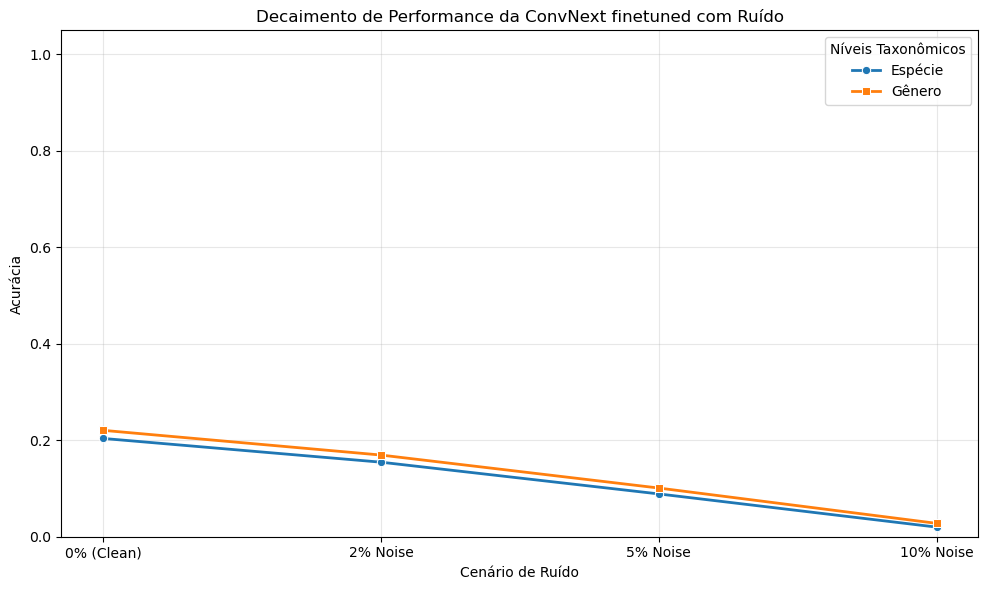

Carregando modelo: ConvNext from scratch
⚙️  Cache não encontrado. Buscando arquivos Parquet em: '/'...
Carregando mapas...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext from scratch.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext from scratch_noise2.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext from scratch_noise5.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext from scratch_noise10.parquet...
💾 Tabela consolidada salva no cache para as próximas chamadas: results_reports/summary_degradation_convnext_from_scratch.csv

--- Tabela de Resultados Consolidados ---
        Ruído  Acc Espécie  Acc Gênero
0  0% (Clean)     0.120106    0.123457
1    2% Noise     0.039055    0.041714
2    5% Noise     0.006700    0.009033
3   10% Noise     0.003521    0.005604


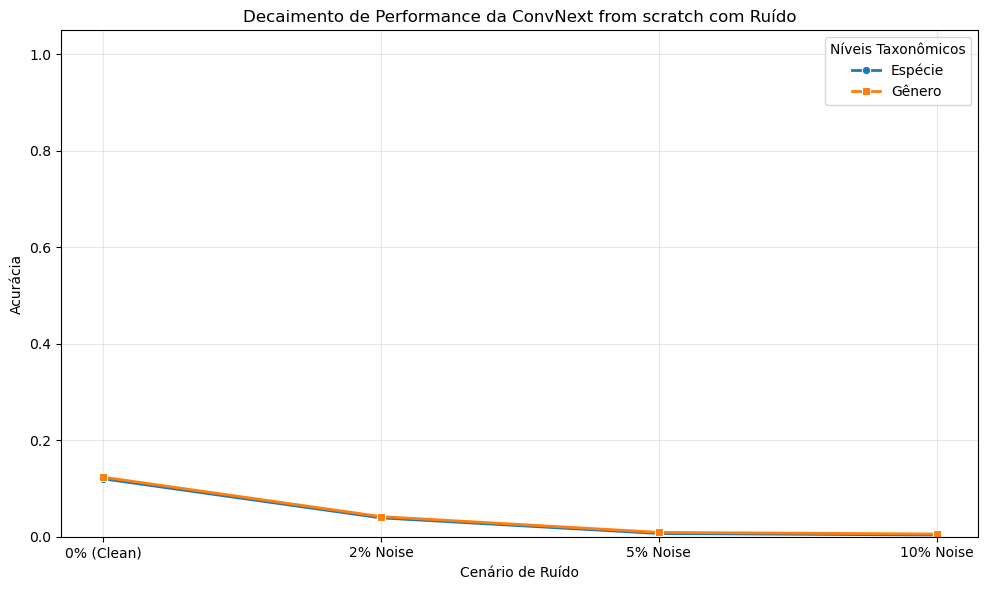

Carregando modelo: ConvNext transfer from genus
⚙️  Cache não encontrado. Buscando arquivos Parquet em: '/'...
Carregando mapas...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext transfer from genus.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext transfer from genus_noise2.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext transfer from genus_noise5.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ConvNext transfer from genus_noise10.parquet...
💾 Tabela consolidada salva no cache para as próximas chamadas: results_reports/summary_degradation_convnext_transfer_from_genus.csv

--- Tabela de Resultados Consolidados ---
        Ruído  Acc Espécie  Acc Gênero
0  0% (Clean)     0.034899    0.046765
1    2% Noise     0.011884    0.022894
2    5% Noise     0.005517    0.015272
3   10% Noise     0.004314    0.012274


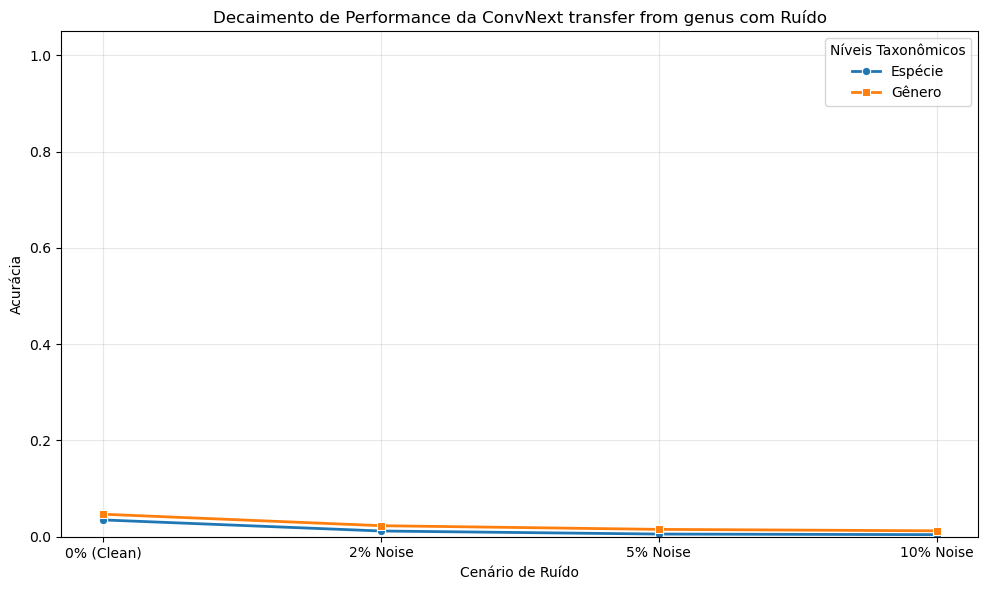

Carregando modelo: ResNet50
⚙️  Cache não encontrado. Buscando arquivos Parquet em: '/'...
Carregando mapas...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ResNet50.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ResNet50_noise2.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ResNet50_noise5.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ResNet50_noise10.parquet...
💾 Tabela consolidada salva no cache para as próximas chamadas: results_reports/summary_degradation_resnet50.csv

--- Tabela de Resultados Consolidados ---
        Ruído  Acc Espécie  Acc Gênero
0  0% (Clean)     0.666668    0.751597
1    2% Noise     0.507480    0.583612
2    5% Noise     0.184678    0.233109
3   10% Noise     0.017200    0.041582


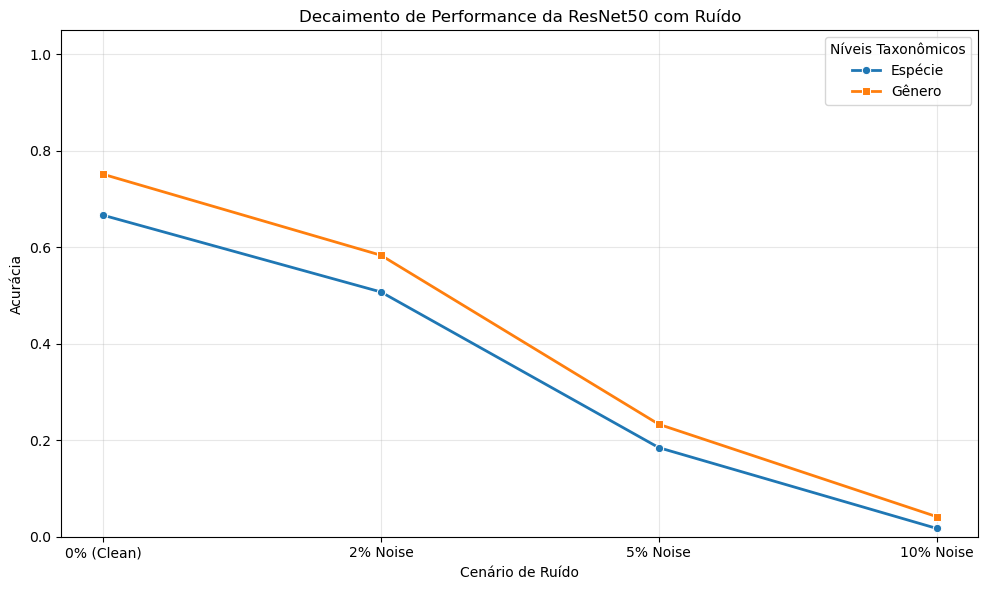

Carregando modelo: ResNet50_finetuned
⚙️  Cache não encontrado. Buscando arquivos Parquet em: '/'...
Carregando mapas...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ResNet50_finetuned.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ResNet50_finetuned_noise2.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ResNet50_finetuned_noise5.parquet...
   Lendo e calculando métricas de: resultados_inferencia_long_reads_ResNet50_finetuned_noise10.parquet...
💾 Tabela consolidada salva no cache para as próximas chamadas: results_reports/summary_degradation_resnet50_finetuned.csv

--- Tabela de Resultados Consolidados ---
        Ruído  Acc Espécie  Acc Gênero
0  0% (Clean)     0.220961    0.236500
1    2% Noise     0.194102    0.207736
2    5% Noise     0.155807    0.167419
3   10% Noise     0.089463    0.098179


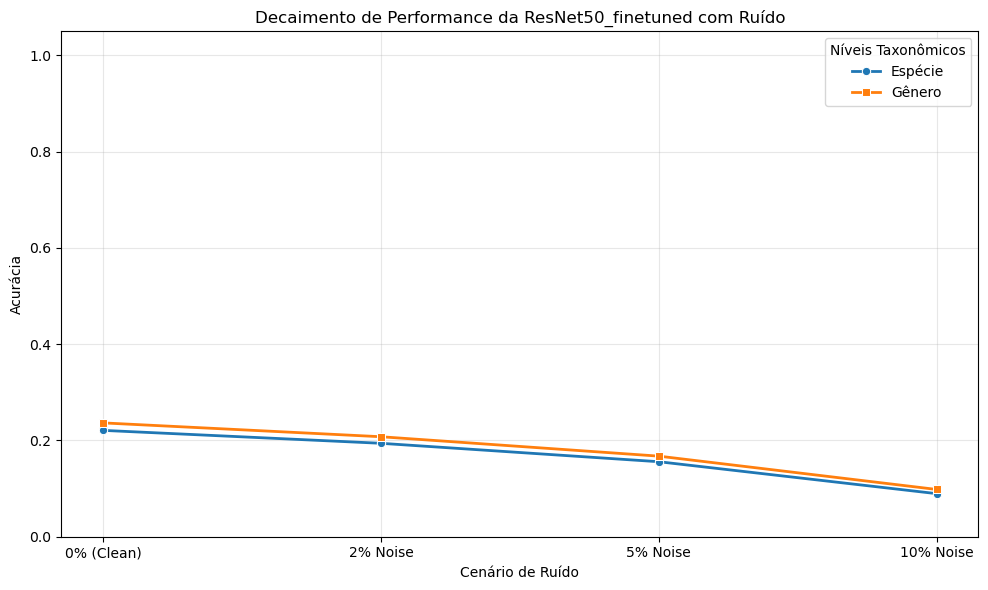

In [31]:
for model_dict in models:
    model_name = model_dict["model_name"]
    print(f"Carregando modelo: {model_name}")
    generate_graph_noise(model_name)

🚀 Iniciando consolidação de todos os modelos...
   📊 Processando: ConvNext finetuned
   📊 Processando: ConvNext from scratch
   📊 Processando: ConvNext transfer from genus
   📊 Processando: ResNet50
   📊 Processando: ResNet50_finetuned


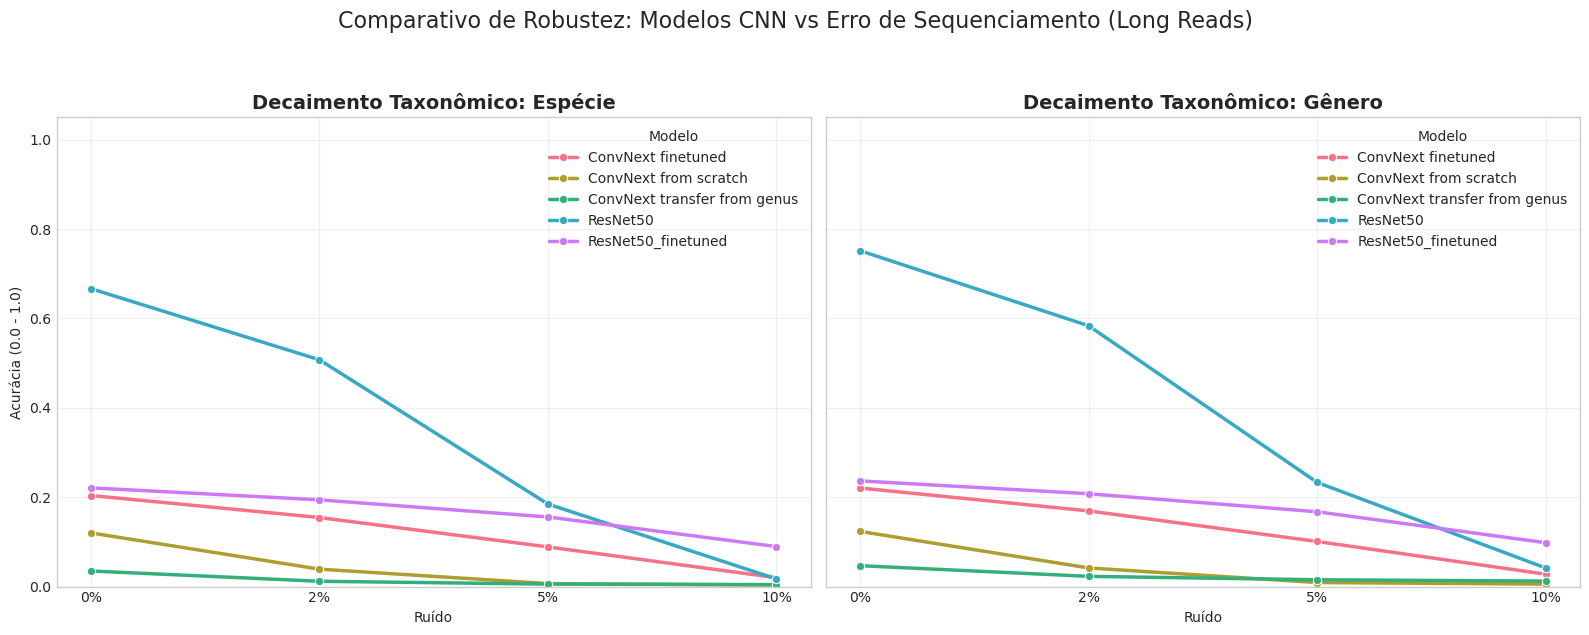

In [33]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def compare_all_models_degradation(base_dir=""):
    # 1. Definição dos modelos e níveis de ruído
    modelos = [
        "ConvNext finetuned", 
        "ConvNext from scratch", 
        "ConvNext transfer from genus", 
        "ResNet50", 
        "ResNet50_finetuned"
    ]
    
    niveis = {
        "0%": "", # O arquivo original geralmente não tem sufixo _noise0
        "2%": "_noise2",
        "5%": "_noise5",
        "10%": "_noise10"
    }

    # Carregamento do Mapa de Taxonomia para cálculo de Gênero
    TAX_PATH = "taxonomia_recuperada.csv"
    if not os.path.exists(TAX_PATH):
        print(f"❌ Erro: {TAX_PATH} não encontrado.")
        return
    
    df_tax = pd.read_csv(TAX_PATH)
    sp_to_gn = dict(zip(df_tax['species_id'], df_tax['genus_id']))

    all_results = []

    print("🚀 Iniciando consolidação de todos os modelos...")

    for model_name in modelos:
        print(f"   📊 Processando: {model_name}")
        for label, sufixo in niveis.items():
            # Tenta encontrar o arquivo (com ou sem o sufixo noise0)
            file_name = f"resultados_inferencia_long_reads_{model_name}{sufixo}.parquet"
            path = os.path.join(base_dir, file_name)
            
            # Fallback para o caso do 0% não ter o sufixo no nome do arquivo
            if not os.path.exists(path) and label == "0%":
                path = os.path.join(base_dir, f"resultados_inferencia_long_reads_{model_name}.parquet")

            if os.path.exists(path):
                df = pd.read_parquet(path)
                
                # Lógica de TaxID (Index + 1)
                truth_sp = df['real_tax_id'] if df['real_tax_id'].min() >= 1 else df['real_tax_id'] + 1
                pred_sp = df['pred_majority_vote'] + 1
                
                # Acurácia Espécie
                acc_sp = (truth_sp == pred_sp).mean()
                
                # Acurácia Gênero
                truth_gn = truth_sp.map(sp_to_gn)
                pred_gn = pred_sp.map(sp_to_gn)
                valid = truth_gn.notna() & pred_gn.notna()
                acc_gn = (truth_gn[valid] == pred_gn[valid]).mean() if valid.any() else 0.0
                
                all_results.append({
                    "Modelo": model_name,
                    "Ruído": label,
                    "Acurácia": acc_sp,
                    "Nível": "Espécie"
                })
                all_results.append({
                    "Modelo": model_name,
                    "Ruído": label,
                    "Acurácia": acc_gn,
                    "Nível": "Gênero"
                })
            else:
                print(f"      ⚠️  Arquivo não encontrado: {file_name}")

    df_plot = pd.DataFrame(all_results)

    # 2. Configuração Visual do Slide
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    
    # Cores distintas para cada modelo
    palette = sns.color_palette("husl", len(modelos))

    for i, nivel in enumerate(["Espécie", "Gênero"]):
        data_subset = df_plot[df_plot["Nível"] == nivel]
        
        sns.lineplot(
            data=data_subset, 
            x="Ruído", 
            y="Acurácia", 
            hue="Modelo", 
            marker="o", 
            linewidth=2.5,
            palette=palette,
            ax=axes[i]
        )
        
        axes[i].set_title(f"Decaimento Taxonômico: {nivel}", fontsize=14, fontweight='bold')
        axes[i].set_ylim(0, 1.05)
        axes[i].set_ylabel("Acurácia (0.0 - 1.0)")
        axes[i].grid(True, alpha=0.3)

    plt.suptitle("Comparativo de Robustez: Modelos CNN vs Erro de Sequenciamento (Long Reads)", fontsize=16, y=1.05)
    plt.tight_layout()
    
    # Salva para o slide
    os.makedirs("results_plots", exist_ok=True)
    plt.savefig("results_plots/comparativo_global_robustez.png", dpi=300, bbox_inches='tight')
    plt.show()

# Executar a comparação
compare_all_models_degradation()